<a href="https://colab.research.google.com/github/Hema1802-03/Hema1802-03/blob/main/autoencoder_working_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os
import zipfile
import glob

# Step 1: Check whether ZIP exists
zip_path = "/content/dataset nn.zip"
extract_path = "/content/network_dataset"

if not os.path.exists(zip_path):
    print("❌ ZIP file not found:", zip_path)

else:
    print("✅ ZIP file found!")


    try:
        with zipfile.ZipFile(zip_path, "r") as z:
            all_files = z.namelist()

            print("Total files inside ZIP:", len(all_files))
            print("\nFirst 20 files inside ZIP:")
            for f in all_files[:20]:
                print(f)

            os.makedirs(extract_path, exist_ok=True)
            z.extractall(extract_path)

        print("\n✅ Extraction completed!")


        csv_files = glob.glob(
            os.path.join(extract_path, "**", "*.csv"),
            recursive=True
        )

        print("\nNumber of CSV files found:", len(csv_files))

        for i, f in enumerate(csv_files, start=1):
            size_mb = os.path.getsize(f) / (1024 * 1024)
            print(f"{i}. {os.path.basename(f)} ({size_mb:.2f} MB)")
            print("   Path:", f)

        # Step 4: Report status
        if len(csv_files) == 8:
            print("\n SUCCESS! All CSV files are ready.")
        elif len(csv_files) > 0:
            print(f"\n⚠️ Found {len(csv_files)} CSV files instead of 8.")
        else:
            print("\n❌ No CSV files found. Check the ZIP contents above.")

    except zipfile.BadZipFile:
        print("❌ The ZIP file is corrupted or invalid.")
    except Exception as e:
        print("❌ Error:", str(e))

✅ ZIP file found!
Total files inside ZIP: 8

First 20 files inside ZIP:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv

✅ Extraction completed!

Number of CSV files found: 8
1. Wednesday-workingHours.pcap_ISCX.csv (214.74 MB)
   Path: /content/network_dataset/Wednesday-workingHours.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (73.55 MB)
   Path: /content/network_dataset/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv (55.62 MB)
   Path: /content/network_dataset/Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Tuesday-WorkingHours.pcap_ISCX.csv (128.82 MB)
   Path: /content/network_dataset/Tuesday-WorkingHours.pc

In [7]:
# ============================================
# NETWORK INTRUSION DETECTION
# STEP 2: LOAD AND PREPARE DATASET
# ============================================

import os
import glob
import gc
import numpy as np
import pandas as pd

# 1. Find all CSV files
extract_path = "/content/network_dataset"

csv_files = sorted(
    glob.glob(
        os.path.join(extract_path, "**", "*.csv"),
        recursive=True
    )
)

print("Number of CSV files:", len(csv_files))

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found. Check the extraction folder."
    )

# 2. Read a manageable sample from each file
# This avoids loading every large CSV into RAM.
sampled_data = []

for file in csv_files:
    print("\nReading:", os.path.basename(file))

    file_samples = []
    rows_sampled = 0

    try:
        for chunk in pd.read_csv(
            file,
            chunksize=100_000,
            encoding="latin1",
            low_memory=True
        ):
            # Clean column names
            chunk.columns = chunk.columns.str.strip()

            # Sample up to 1,000 rows per chunk
            n = min(1000, len(chunk))

            if n > 0:
                sample = chunk.sample(
                    n=n,
                    random_state=42
                )
                file_samples.append(sample)
                rows_sampled += len(sample)

            # Limit sample size from each file
            if rows_sampled >= 10_000:
                break

            del chunk

        if file_samples:
            file_df = pd.concat(
                file_samples,
                ignore_index=True
            )
            sampled_data.append(file_df)

            print("Rows sampled:", len(file_df))

        del file_samples
        gc.collect()

    except Exception as e:
        print("Error reading file:", file)
        print(e)

# 3. Combine samples
if not sampled_data:
    raise ValueError("No data could be loaded from the CSV files.")

df = pd.concat(
    sampled_data,
    ignore_index=True
)

del sampled_data
gc.collect()

# 4. Clean column names
df.columns = df.columns.str.strip()

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

# 5. Find the label column
label_candidates = [
    col for col in df.columns
    if col.strip().lower() in ["label", "labels", "class"]
]

if not label_candidates:
    print("\nAvailable columns:")
    print(df.columns.tolist())
    raise ValueError(
        "Could not identify the label column."
    )

label_col = label_candidates[0]


print("\nLabel column:", label_col)
print("\nTraffic label distribution:")
print(df[label_col].value_counts().head(20))


print("\nNumber of features including label:", len(df.columns))
print("\nFirst five rows:")
display(df.head())

Number of CSV files: 8

Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows sampled: 3000

Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows sampled: 3000

Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows sampled: 2000

Reading: Monday-WorkingHours.pcap_ISCX.csv
Rows sampled: 6000

Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows sampled: 3000

Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows sampled: 2000

Reading: Tuesday-WorkingHours.pcap_ISCX.csv
Rows sampled: 5000

Reading: Wednesday-workingHours.pcap_ISCX.csv
Rows sampled: 7000

Dataset loaded successfully!
Dataset shape: (31000, 79)

Label column: Label

Traffic label distribution:
Label
BENIGN                        25360
DoS Hulk                       2329
PortScan                       1665
DDoS                           1239
DoS GoldenEye                   109
FTP-Patator                      84
DoS slowloris                    68
SSH-Patator    

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,1794056,3,4,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
1,80,1876817,3,5,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
2,80,877593,3,6,26,11601,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
3,80,68745,3,6,26,11601,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
4,80,82777213,8,6,56,11601,20,0,7.000000,5.656854,...,20,2.0,0.0,2,2,40500000.0,45200000.0,72500000,8494938,DDoS


In [8]:
# ============================================
# STEP 3: DATA PREPROCESSING
# ============================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Clean column names
df.columns = df.columns.str.strip()

# 2. Identify the label column
label_candidates = [
    col for col in df.columns
    if col.strip().lower() in ["label", "labels", "class"]
]

if not label_candidates:
    raise ValueError("Label column not found!")

label_col = label_candidates[0]

print("Label column:", label_col)

# 3. Display original labels
print("\nOriginal traffic labels:")
print(df[label_col].value_counts())

# 4. Create binary labels
# BENIGN = 0, all other labels = 1
df["Target"] = (
    df[label_col]
    .astype(str)
    .str.strip()
    .str.upper()
    .ne("BENIGN")
    .astype(int)
)

print("\nBinary label distribution:")
print(df["Target"].value_counts())

# 5. Separate features and target
X = df.drop(columns=[label_col, "Target"])
y = df["Target"]

# 6. Convert all features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values with each feature's median
X = X.fillna(X.median()).fillna(0)

# Remove constant features
constant_cols = X.columns[X.nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)

print("\nConstant features removed:", len(constant_cols))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# 7. Split into training and testing sets
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Use only benign samples to train the Autoencoder
X_train = X_train_full.loc[y_train_full == 0]

print("\nTraining samples before filtering:", len(X_train_full))
print("Benign training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nPreprocessing completed successfully!")

Label column: Label

Original traffic labels:
Label
BENIGN                        25360
DoS Hulk                       2329
PortScan                       1665
DDoS                           1239
DoS GoldenEye                   109
FTP-Patator                      84
DoS slowloris                    68
SSH-Patator                      55
DoS Slowhttptest                 51
Bot                              20
Web Attack ï¿½ Brute Force       15
Web Attack ï¿½ XSS                5
Name: count, dtype: int64

Binary label distribution:
Target
0    25360
1     5640
Name: count, dtype: int64

Constant features removed: 8
Feature matrix shape: (31000, 70)
Target shape: (31000,)

Training samples before filtering: 24800
Benign training samples: 20288
Testing samples: 6200

Preprocessing completed successfully!


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on benign training traffic
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("Scaling completed successfully!")

Training data shape: (20288, 70)
Testing data shape: (6200, 70)
Scaling completed successfully!


In [10]:
# ============================================
# STEP 6: BUILD THE AUTOENCODER
# ============================================

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Number of input features
input_dim = X_train_scaled.shape[1]

# Input layer
input_layer = Input(shape=(input_dim,), name="Input_Layer")

# Encoder
encoded = Dense(32, activation="relu", name="Encoder_32")(input_layer)
encoded = Dense(16, activation="relu", name="Encoder_16")(encoded)
encoded = Dense(8, activation="relu", name="Bottleneck")(encoded)

# Decoder
decoded = Dense(16, activation="relu", name="Decoder_16")(encoded)
decoded = Dense(32, activation="relu", name="Decoder_32")(decoded)
decoded = Dense(input_dim, activation="linear", name="Output_Layer")(decoded)

# Create model
autoencoder = Model(input_layer, decoded, name="Network_Intrusion_Autoencoder")

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Display architecture
autoencoder.summary()

Model: "Network_Intrusion_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 70)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_32 (Dense)              │ (None, 32)             │         2,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_16 (Dense)              │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_16 (Dense)              │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_32 (Dense)              │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 70)             │         2,310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,934 (23.18 KB)

 Trainable params: 5,934 (23.18 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# ============================================
# STEP 7: TRAIN THE AUTOENCODER
# ============================================

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=15,
    batch_size=256,
    validation_split=0.2,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1
)

print("\nAutoencoder training completed!")

Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.8175 - val_loss: 1.2697
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6216 - val_loss: 1.1046
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4874 - val_loss: 0.9929
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4041 - val_loss: 0.9717
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3676 - val_loss: 0.9534
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3437 - val_loss: 0.9567
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3213 - val_loss: 0.9709
Epoch 8/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3025 - val_loss: 0.9648

Autoencoder training completed!


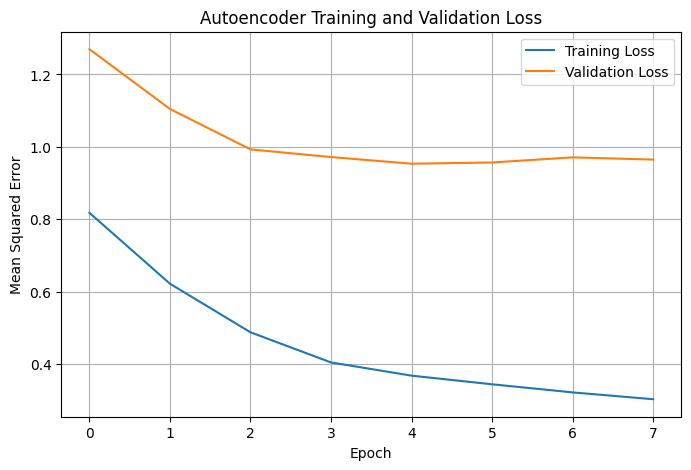

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
import numpy as np

# Reconstruct benign training data
X_train_reconstructed = autoencoder.predict(
    X_train_scaled,
    verbose=0
)

# Calculate Mean Squared Reconstruction Error
train_errors = np.mean(
    np.square(X_train_scaled - X_train_reconstructed),
    axis=1
)

print("Training reconstruction errors calculated!")
print("Mean error:", np.mean(train_errors))
print("Maximum error:", np.max(train_errors))

Training reconstruction errors calculated!
Mean error: 0.47224583555633637
Maximum error: 2783.273623930628


In [14]:
threshold = np.percentile(train_errors, 95)

print("Detection threshold:", threshold)

Detection threshold: 0.7560794741650757


In [15]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled,
    verbose=0
)

test_errors = np.mean(
    np.square(X_test_scaled - X_test_reconstructed),
    axis=1
)

print("Test reconstruction errors calculated!")
print("Number of test samples:", len(test_errors))

Test reconstruction errors calculated!
Number of test samples: 6200


In [16]:
# 0 = BENIGN
# 1 = ATTACK

y_pred = (test_errors > threshold).astype(int)

print("Predictions generated successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!

First 20 predictions:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0]


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8562903225806452
Precision: 0.66078697421981
Recall: 0.4317375886524823
F1-score: 0.5222520107238606

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.92      5072
           1       0.66      0.43      0.52      1128

    accuracy                           0.86      6200
   macro avg       0.77      0.69      0.72      6200
weighted avg       0.84      0.86      0.84      6200


Confusion Matrix:
[[4822  250]
 [ 641  487]]


In [18]:
# STEP 14: THRESHOLD COMPARISON

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

percentiles = [80, 85, 90, 92, 95, 97, 99]

results = []

for p in percentiles:

    # Calculate threshold from benign training errors
    temp_threshold = np.percentile(train_errors, p)

    # Generate predictions
    temp_pred = (test_errors > temp_threshold).astype(int)

    # Evaluate
    results.append({
        "Percentile": p,
        "Threshold": temp_threshold,
        "Accuracy": accuracy_score(y_test, temp_pred),
        "Precision": precision_score(
            y_test, temp_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, temp_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, temp_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Threshold comparison:")
display(results_df.round(4))

Threshold comparison:


,Percentile,Threshold,Accuracy,Precision,Recall,F1 Score
0,80,0.2293,0.7521,0.3705,0.5186,0.4322
1,85,0.2920,0.7897,0.4321,0.4965,0.4620
2,90,0.3791,0.8248,0.5203,0.4770,0.4977
3,92,0.5149,0.8366,0.5619,0.4628,0.5075
4,95,0.7561,0.8563,0.6608,0.4317,0.5223
5,97,1.0169,0.8665,0.7517,0.3972,0.5197
6,99,4.3143,0.8323,0.7785,0.1090,0.1913
